In [82]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm
import tensorflow as tf
import joblib
from scipy.ndimage import convolve



### 参数设置（用户可修改部分）

In [83]:

IMAGE_PATH = 'F:/B208/High_density/ML_generation/image_train/img41.png'
OUTPUT_IMAGE_PATH = 'F:/B208/High_density/ML_generation/image_test/img41.png'
SAVE_PATH = "F:/B208/High_density/ML_generation/density_map/img41.txt"
WIDTH = 4
LENGTH = 4
IMG_SIZE = 512  # 图像的大小（假设图像为512x512）

# 加载模型
MODEL_SAVE_PATH = 'F:/B208/High_density/ML_generation/Model/RandomForestRegressor.pkl'
rf_model_loaded = joblib.load(MODEL_SAVE_PATH)

In [84]:

# 读取灰度图像
def load_image(image_path):
    img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
    return img.astype(np.float32) / 255.0 if img is not None else None

# 计算统计特征，仅保留 Mean
def compute_mean(img):
    return np.mean(img)

# 读取和预处理图像
image = tf.io.read_file(IMAGE_PATH)
image = tf.image.decode_png(image, channels=1)
image = tf.image.resize(image, [IMG_SIZE, IMG_SIZE])
image = tf.cast(image, tf.float32) / 255.0
image = np.array(image)

# 确保是 2D 数组
image = np.squeeze(image)

# 创建特征列表
means = []

# 计算每个块的 Mean
for y_start in tqdm(range(0, image.shape[0] - LENGTH + 1, LENGTH), desc="Processing Image", unit="block"):
    for x_start in range(0, image.shape[1] - WIDTH + 1, WIDTH):
        block_image = image[y_start:y_start + LENGTH, x_start:x_start + WIDTH]
        mean_value = compute_mean(block_image)
        means.append(mean_value)

# 转换为 numpy 数组
train_images = np.array(means).reshape(-1, 1)

Processing Image: 100%|██████████| 128/128 [00:00<00:00, 1898.41block/s]


In [85]:
# Check if the model is fitted
if hasattr(rf_model_loaded, 'feature_importances_'):
    print("Model is fitted and ready to predict.")
else:
    print("Model is not fitted. You need to fit it first.")

Model is fitted and ready to predict.


In [86]:
# 确保模型特征数匹配
if rf_model_loaded.n_features_in_ != 1:
    raise ValueError(f"Model expects {rf_model_loaded.n_features_in_} features, but received 1.")

In [87]:

# 进行预测
predicted_density = rf_model_loaded.predict(train_images)

print(predicted_density)


d:\anaconda3\envs\tensorflow\lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(


[68.7985625  21.33617902  7.24191042 ... 16.26793576 59.4031629
 36.10261984]


In [88]:
# 保存每个切块的坐标和预测密度到文件
with open(SAVE_PATH, 'w') as file:
    # 遍历每个4x4的块并保存结果
    density_idx = 0
    for y_start in range(0, image.shape[0] - LENGTH + 1, LENGTH):  # y_start 从 0 到 512 - 4
        for x_start in range(0, image.shape[1] - WIDTH + 1, WIDTH):  # x_start 从 0 到 512 - 4
            # 获取对应的预测密度值
            density = predicted_density[density_idx]
            
            # 计算方块的坐标 (x_start, x_end, y_start, y_end)
            x_end = x_start + WIDTH
            y_end = y_start + LENGTH
            
            # 写入坐标和预测密度到文件
            file.write(f"{x_start} {x_end} {y_start} {y_end} {density}\n")
            
            density_idx += 1  # 增加密度索引

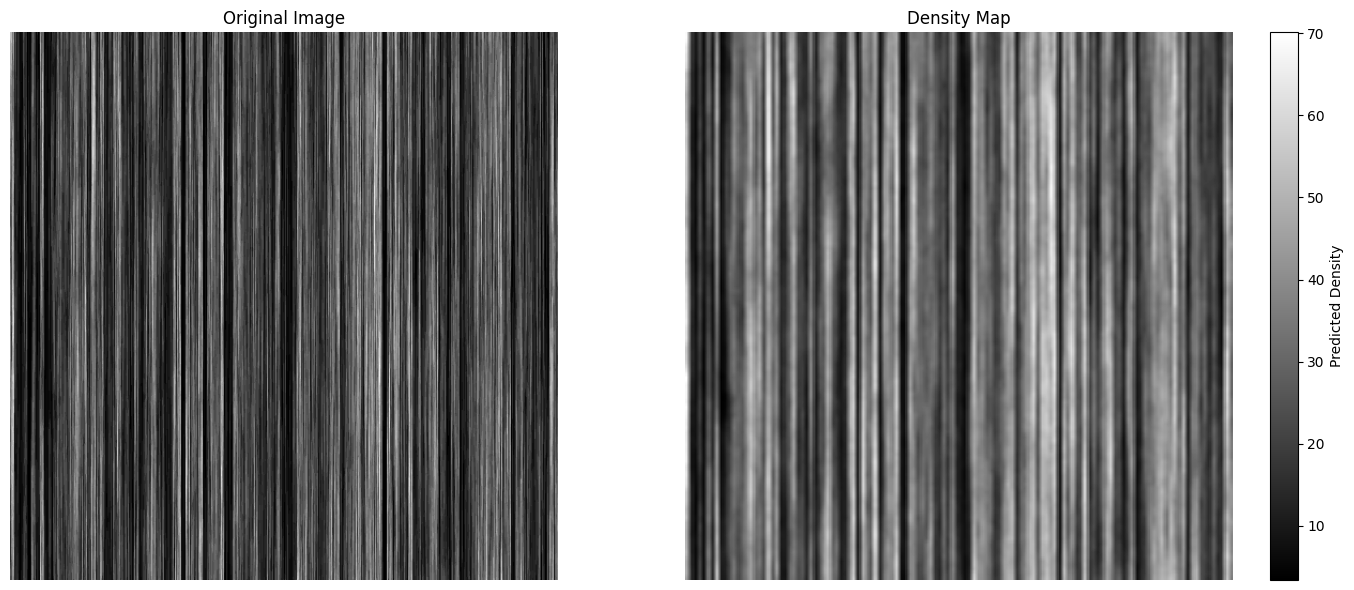

In [89]:
density_map = np.zeros((image.shape[0], image.shape[1]))

# 填充密度图
density_idx = 0
for y_start in range(0, image.shape[0] - LENGTH + 1, LENGTH):
    for x_start in range(0, image.shape[1] - WIDTH + 1, WIDTH):
        # 获取当前窗口的预测密度值
        density = predicted_density[density_idx]

        # 将预测的密度值放入对应窗口区域的密度图中
        density_map[y_start:y_start + LENGTH, x_start:x_start + WIDTH] = density

        # 增加密度索引
        density_idx += 1

kernel = np.ones((5, 5)) / 25  # 5x5均值卷积核
density_map = convolve(density_map, kernel)
#image = convolve(image, kernel)
# 可视化：展示原图和密度图
plt.figure(figsize=(15, 6))

# 显示原图

plt.subplot(1, 2, 1)
plt.imshow(image, cmap='gray')
plt.title("Original Image")
plt.axis('off')

# 显示密度热力图（平滑后的）
plt.subplot(1, 2, 2)
plt.imshow(density_map, cmap='gray', interpolation='nearest')
plt.colorbar(label="Predicted Density")
plt.title("Density Map")
plt.axis('off')

# 保存密度热力图
plt.tight_layout()
plt.savefig(OUTPUT_IMAGE_PATH)
plt.show()